Fig4. 2D-plot of uncertainty: GRMHD, axion-signal: Amplitude and phase.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
import os, sys

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.libanaly import fit_gaussian2

In [2]:
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams[
    "text.latex.preamble"
] = r"""
\usepackage{amsmath}
\usepackage{amssymb}
"""
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Times New Roman"  # 设置正常文本的字体
plt.rcParams["mathtext.it"] = "Times New Roman:italic"  # 设置斜体文本的字体
plt.rcParams["mathtext.bf"] = "Times New Roman:bold"  # 设置粗体文本的字体

In [3]:
A_params_dict = np.load(
    "../GRMHD/data_out/A_params_dict_nonan.npy", allow_pickle=True
).item()
phi0_params_dict = np.load(
    "../GRMHD/data_out/phi0_params_dict_nonan.npy", allow_pickle=True
).item()

In [4]:
condition = np.load("../EHT-Imaging/data_out/condition.npy", allow_pickle=True)

In [5]:
A_1d_r_9 = np.load("../GRMHD/data_out/A_1d_r=9_alpha=0.3_res=400.npy")
phi0_1d_r_9 = np.load("../GRMHD/data_out/phi0_1d_r=9_alpha=0.3_res=400.npy")

In [6]:
# diffs_axion_evpa_std = np.load("diffs_axion_evpa_std.npy")

In [7]:
def Plot_Background_NoNorm(
    fig,
    ax,
    array2d,
    xy_tick_labelsize=14,
    cbar_tick_labelsize=12,
    cbar_label_fontsize=16,
    cbar_label_pad=20,
    cbar_label_y=0.5,
    cbar_label_rotation=0,
    cbar_label_text="Value",  # Colorbar 标签文本
    data_vmin=None,  # 颜色映射的最小值 (None则自动)
    data_vmax=None,
    cmap="Greys_r",
    upscale_factor=1,
    phi0=False,
    condition=None,
    title="",
    title_fontsize=16,
    title_y=1.02,
    title_x=0.5,
    fmt=2,
    degree=False,
):  # 颜色映射的最大值 (None则自动)
    """
    绘制背景图，不进行数据归一化，并调整坐标轴和Colorbar的样式。

    参数:
    - fig: matplotlib Figure 对象
    - ax: matplotlib Axes 对象
    - array2d: 二维数组数据 (原始值)
    - xy_tick_labelsize: XY轴刻度数字的字号
    - cbar_tick_labelsize: Colorbar刻度数字的字号
    - cbar_label_fontsize: Colorbar标签的字号
    - cbar_label_pad: Colorbar标签与Colorbar之间的距离 (points)
    - cbar_label_y: Colorbar标签的相对垂直位置 (0.0-1.0, 0.5表示中间)
    - cbar_label_rotation: Colorbar标签的旋转角度
    - cbar_label_text: Colorbar的标签文本
    - data_vmin: pcolormesh的vmin参数 (None则自动确定)
    - data_vmax: pcolormesh的vmax参数 (None则自动确定)
    """

    if upscale_factor != 1:
        if phi0:
            array2d1 = np.cos(array2d)
            array2d2 = np.sin(array2d)
            array2d1 = zoom(array2d1, upscale_factor, order=1)
            array2d2 = zoom(array2d2, upscale_factor, order=1)
            array2d = np.arctan2(array2d2, array2d1)
        else:
            array2d = zoom(array2d, upscale_factor, order=1)  # 线性插值 (order=1)
    if condition is not None:
        condition = zoom(
            condition.astype(float), int(array2d.shape[0] / condition.shape[0]), order=0
        ).astype(bool)

    shape = array2d.shape[0]
    xgrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    ygrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    diff = np.diff(xgrid)[0] / 2.0
    xgrid += diff
    ygrid += diff
    xmesh, ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

    # 数据不再进行归一化

    bkg = ax.pcolormesh(
        xmesh,
        ymesh,
        array2d,  # 使用原始 array2d
        cmap=cmap,
        vmin=data_vmin,  # 使用新的 vmin 参数
        vmax=data_vmax,  # 使用新的 vmax 参数
        shading="auto",
    )

    ax.contour(xgrid, ygrid, condition, levels=1, colors="grey")

    ax.set_aspect("equal")

    # 1. 调整XY轴刻度标签大小
    ax.set_xticks([-15, -10, -5, 0, 5, 10, 15])
    ax.set_yticks([-15, -10, -5, 0, 5, 10, 15])
    ax.tick_params(axis="x", labelsize=xy_tick_labelsize)
    ax.tick_params(axis="y", labelsize=xy_tick_labelsize)

    # 添加Colorbar
    clb = plt.colorbar(bkg, ax=ax, fraction=0.046, pad=0.05)

    # 2. 调整Colorbar刻度标签大小
    clb.ax.tick_params(labelsize=cbar_tick_labelsize)
    if degree:
        formatter = FuncFormatter(lambda x, pos: rf"${x:.{fmt}f}^\circ$")
        clb.ax.yaxis.set_major_formatter(formatter)
    # 3. 调整Colorbar标签的属性
    clb.set_label(
        cbar_label_text,  # 使用新的 cbar_label_text 参数
        labelpad=cbar_label_pad,
        y=cbar_label_y,
        rotation=cbar_label_rotation,
        size=cbar_label_fontsize,
    )

    ax.set_title(title, fontsize=title_fontsize, loc="center", pad=title_y, x=title_x)

    return bkg, clb

In [8]:
for alpha in [0.3]:
    _tmp = np.load(
        f"../GRMHD/data_out/EVPA_cos_fit_result_alpha={alpha}_final_shape=256.npy"
    )
    A_data_list = _tmp[:, :, :, 0]
    A_data_list[A_data_list == 0] = np.nan
    phi0_data_list = _tmp[:, :, :, 1]
    phi0_data_list[phi0_data_list == 0] = np.nan
    A_params = np.apply_along_axis(
        fit_gaussian2,
        0,
        A_data_list,
        rm_nan=True,
        plot_failed=False,
        threshold=np.nan,
        p_value_threshold=0.001,
        bins=20,
        nomean=True,
    )
    phi0_params = np.apply_along_axis(
        fit_gaussian2,
        0,
        phi0_data_list,
        rm_nan=True,
        plot_failed=False,
        angle=True,
        lower_bound=-np.pi,
        upper_bound=np.pi,
        threshold=np.nan,
        p_value_threshold=0.001,
        bins=20,
        nomean=True,
    )  # change it


for i in range(256):
    for j in range(256):
        if np.isnan(A_params[0, i, j]):
            A_params[0, i, j] = np.nanmean(
                [
                    A_params[0, i - 1, j],
                    A_params[0, i + 1, j],
                    A_params[0, i, j - 1],
                    A_params[0, i, j + 1],
                ]
            )
            A_params[1, i, j] = np.nanmean(
                [
                    A_params[1, i - 1, j],
                    A_params[1, i + 1, j],
                    A_params[1, i, j - 1],
                    A_params[1, i, j + 1],
                ]
            )
        if np.isnan(phi0_params[0, i, j]):
            phi0_params[0, i, j] = np.nanmean(
                [
                    phi0_params[0, i - 1, j],
                    phi0_params[0, i + 1, j],
                    phi0_params[0, i, j - 1],
                    phi0_params[0, i, j + 1],
                ]
            )
            phi0_params[1, i, j] = np.nanmean(
                [
                    phi0_params[1, i - 1, j],
                    phi0_params[1, i + 1, j],
                    phi0_params[1, i, j - 1],
                    phi0_params[1, i, j + 1],
                ]
            )

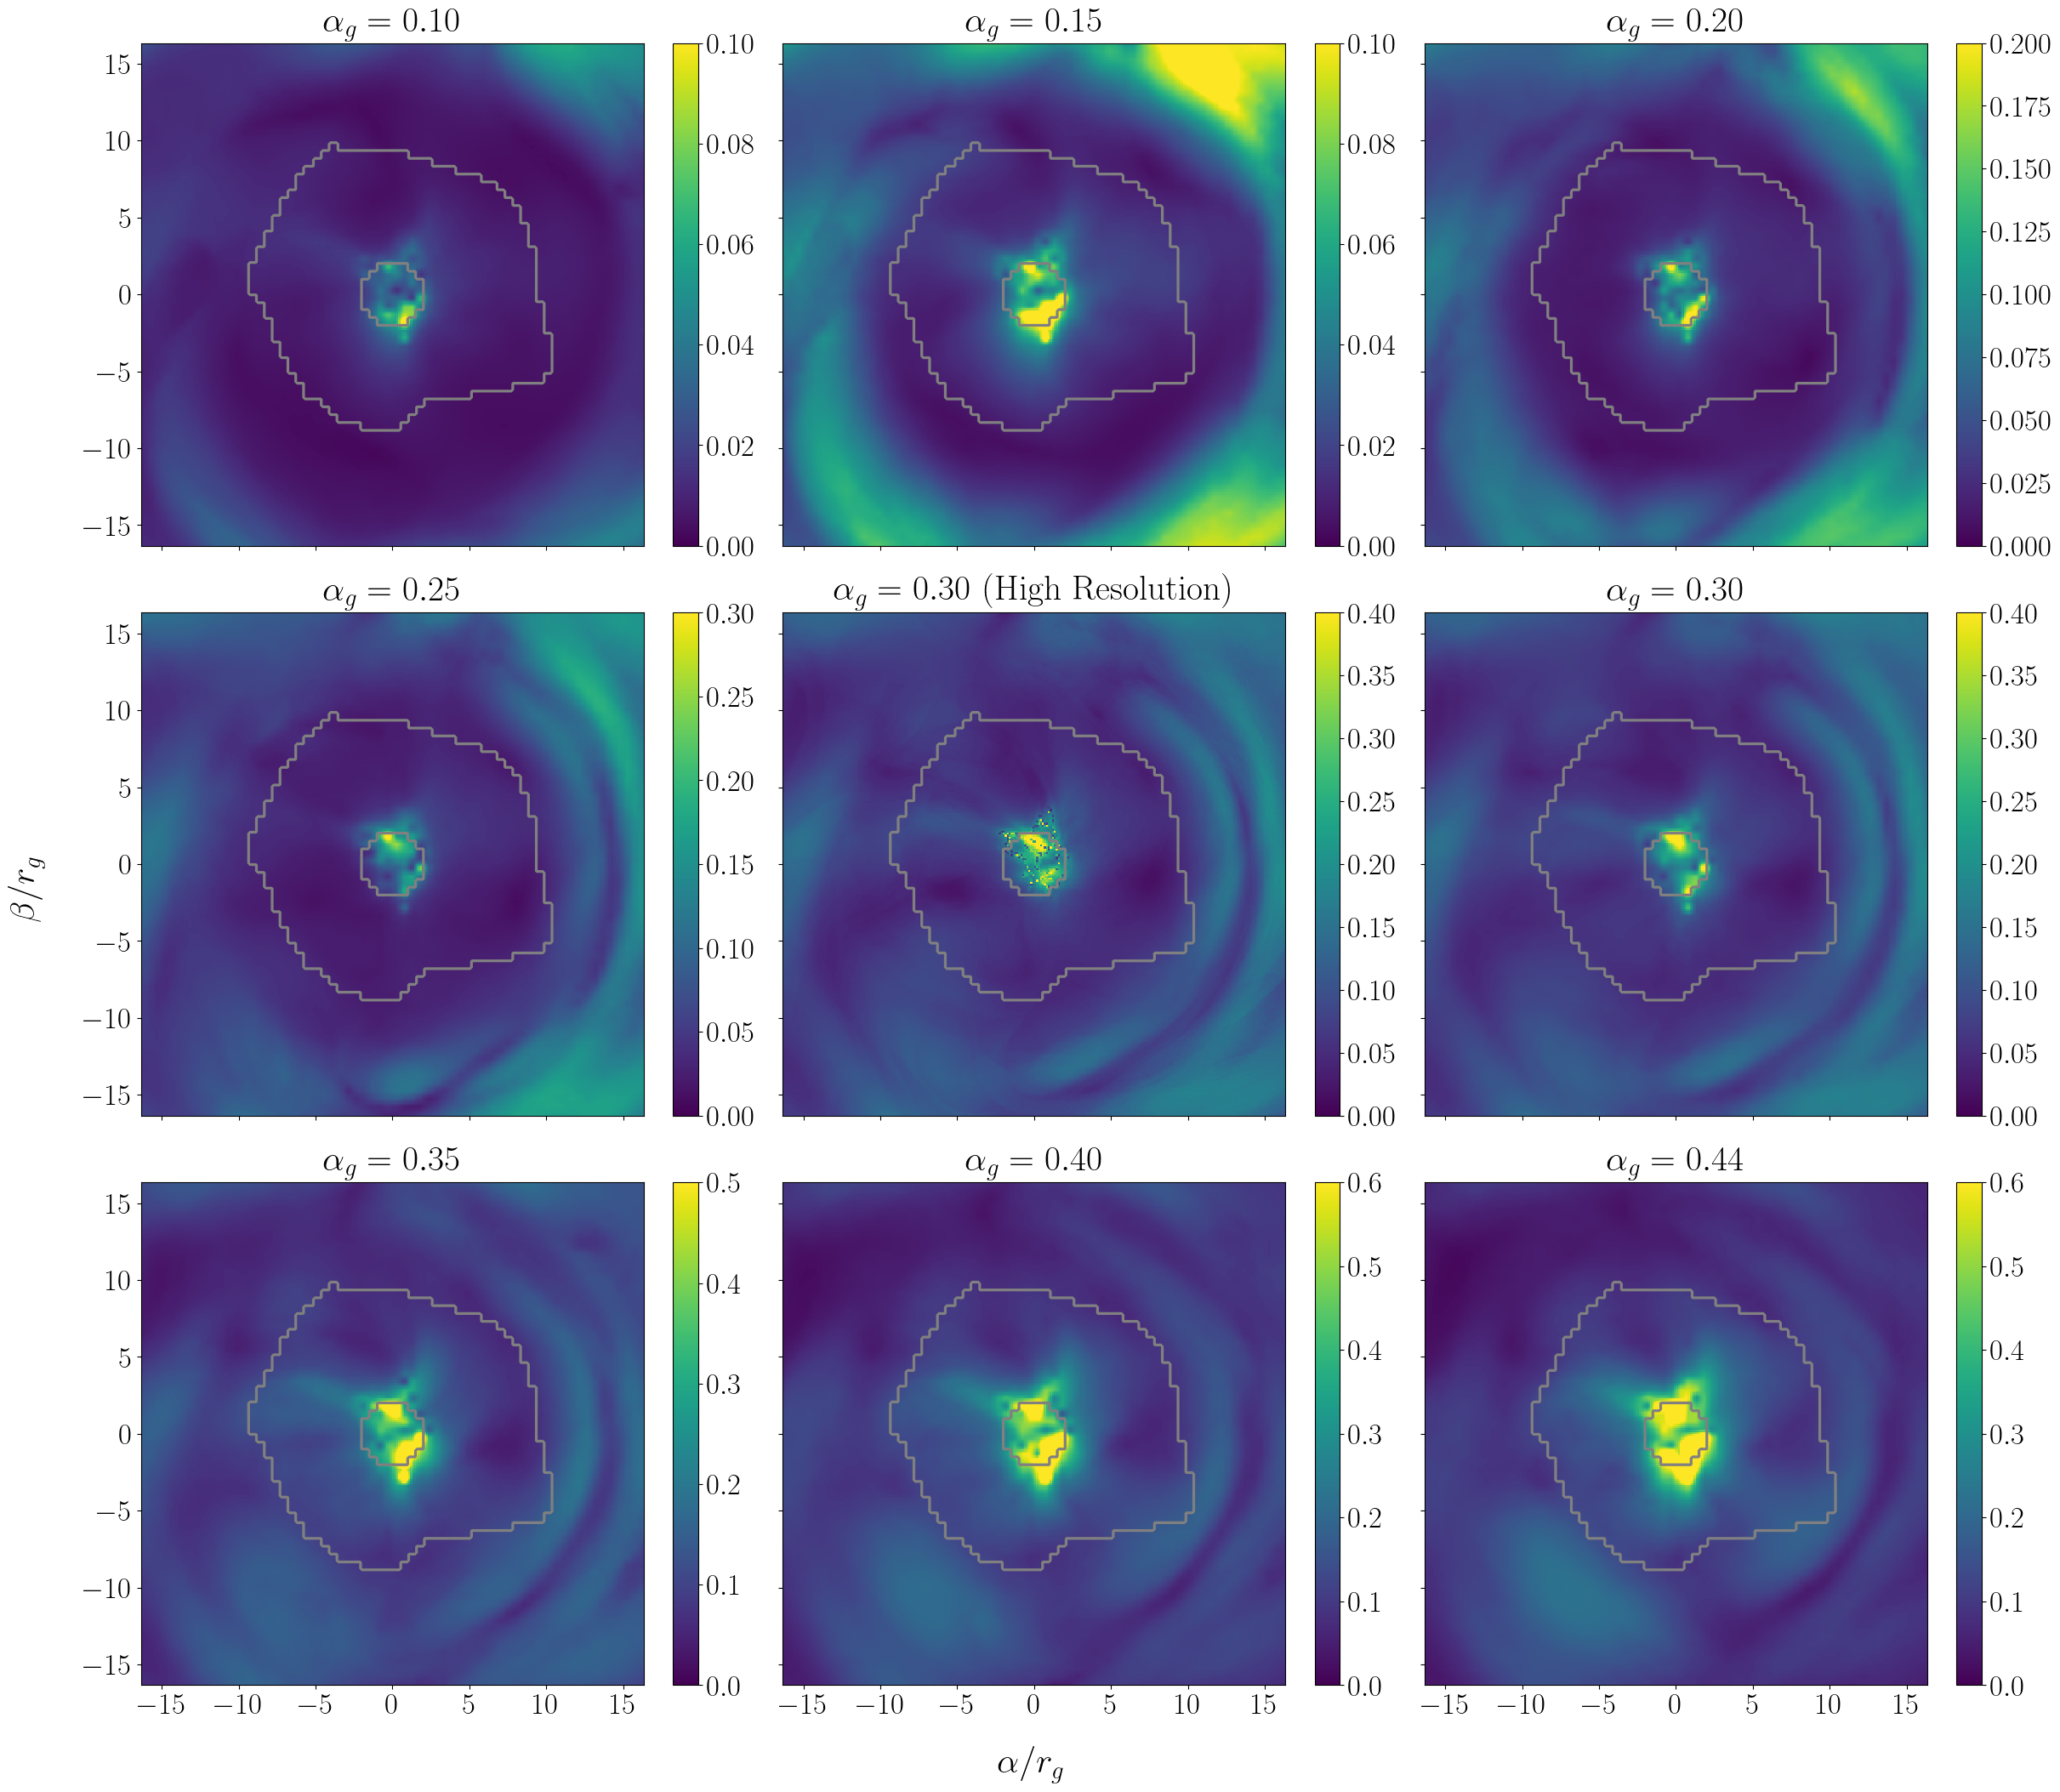

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(24, 21), sharex=True, sharey=True)
alpha_matrix = np.array([[0.1, 0.15, 0.2], [0.25, 0.3, 0.3], [0.35, 0.4, 0.44]])
data_max_matrix = np.array([[0.1, 0.1, 0.2], [0.3, 0.4, 0.4], [0.5, 0.6, 0.6]])
for i in range(3):
    for j in range(3):
        if i == 1 and j == 1:
            Plot_Background_NoNorm(
                fig,
                axes[i, j],
                A_params[1] * 10 * 2 * np.pi,
                xy_tick_labelsize=25,
                cbar_tick_labelsize=25,
                cbar_label_fontsize=20,
                cbar_label_pad=27,
                cbar_label_y=0.5,
                cbar_label_rotation=270,
                cbar_label_text=r"",  # 自定义Colorbar标签
                # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                # 或者您可以手动指定，例如:
                data_vmin=0,
                data_vmax=data_max_matrix[i, j],
                cmap="viridis",
                upscale_factor=1,
                condition=condition,
                title=rf"$\alpha_g={alpha_matrix[i, j]:.2f}$ (High Resolution)",
                title_fontsize=30,
                title_y=10,
                title_x=0.5,
                fmt=2,
            )
        else:
            Plot_Background_NoNorm(
                fig,
                axes[i, j],
                A_params_dict[alpha_matrix[i, j]][1] * 10 * 2 * np.pi,
                xy_tick_labelsize=25,
                cbar_tick_labelsize=25,
                cbar_label_fontsize=20,
                cbar_label_pad=27,
                cbar_label_y=0.5,
                cbar_label_rotation=270,
                cbar_label_text=r"",  # 自定义Colorbar标签
                # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                # 或者您可以手动指定，例如:
                data_vmin=0,
                data_vmax=data_max_matrix[i, j],
                cmap="viridis",
                upscale_factor=4,
                condition=condition,
                title=rf"$\alpha_g={alpha_matrix[i, j]:.2f}$",
                title_fontsize=30,
                title_y=10,
                title_x=0.5,
                fmt=2,
            )
# fig.suptitle(
#     r"Standard of $\mathcal{A}^{\mathrm{tot}}$",
#     fontsize=36,
#     y=0.93,
# )
fig.supxlabel(r"$\alpha/r_g$", fontsize=30, y=-0.001)
fig.supylabel(r"$\beta/r_g$", fontsize=30, x=-0.001)
fig.tight_layout()
# fig.savefig("images/Uncertainty/Std of A.png")

In [94]:
plt.rcParams["text.usetex"] = False

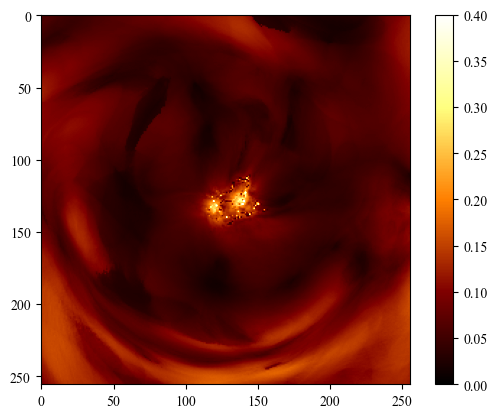

In [ ]:
plt.imshow(A_params[1] / np.pi * 180, cmap="afmhot")
plt.colorbar()
plt.clim(0, 0.4)

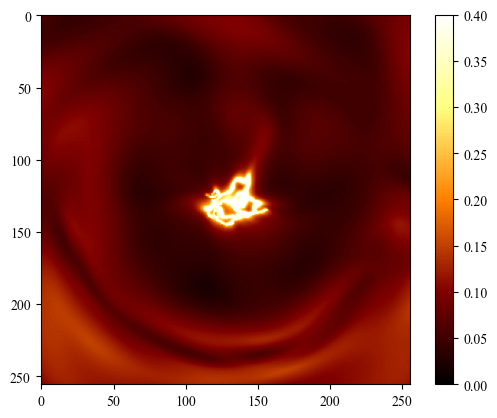

In [ ]:
plt.imshow(np.std(A_data_list, axis=0) / np.pi * 180, cmap="afmhot")
plt.colorbar()
plt.clim(0, 0.4)

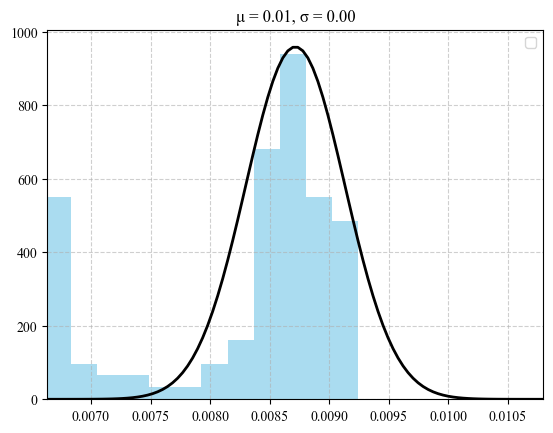

array([0.00871527, 0.00041628])

In [ ]:
fit_gaussian2(
    A_data_list[:, 70, 70],
    rm_nan=True,
    plot_failed=False,
    threshold=np.nan,
    p_value_threshold=0.001,
    plot=True,
    bins=50,
)

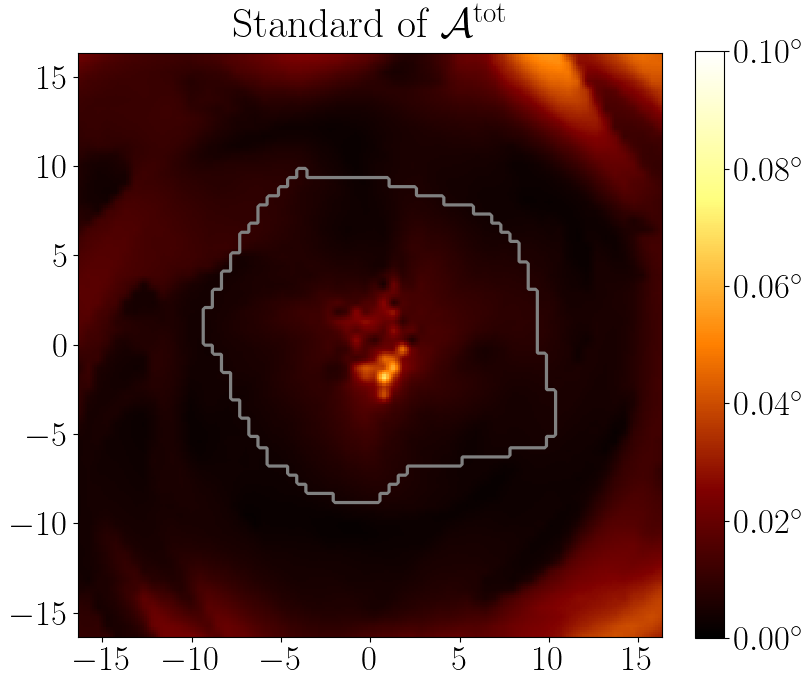

In [44]:
# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
Plot_Background_NoNorm(
    fig,
    ax,
    A_params_dict[0.1][1] / np.pi * 180,
    xy_tick_labelsize=25,
    cbar_tick_labelsize=25,
    cbar_label_fontsize=20,
    cbar_label_pad=27,
    cbar_label_y=0.5,
    cbar_label_rotation=270,
    cbar_label_text=r"",  # 自定义Colorbar标签
    # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
    # 或者您可以手动指定，例如:
    data_vmin=0,
    data_vmax=0.1,
    cmap="afmhot",
    upscale_factor=4,
    condition=condition,
    title=r"Standard of $\mathcal{A}^{\mathrm{tot}}$",
    title_fontsize=30,
    title_y=10,
    title_x=0.5,
    fmt=2,
)

# 添加主图的标题和轴标签（可选）
# ax.set_title("64x64 Data Visualization (No Normalization)", fontsize=16)

# 4. 自动调整布局
fig.tight_layout()
# plt.savefig("fig4_1day_diffs_std.png")
# 5. 显示图像
plt.show()

In [17]:
np.nanmin(phi0_params_dict[0.1][0])

np.float64(-3.2323495232927666)

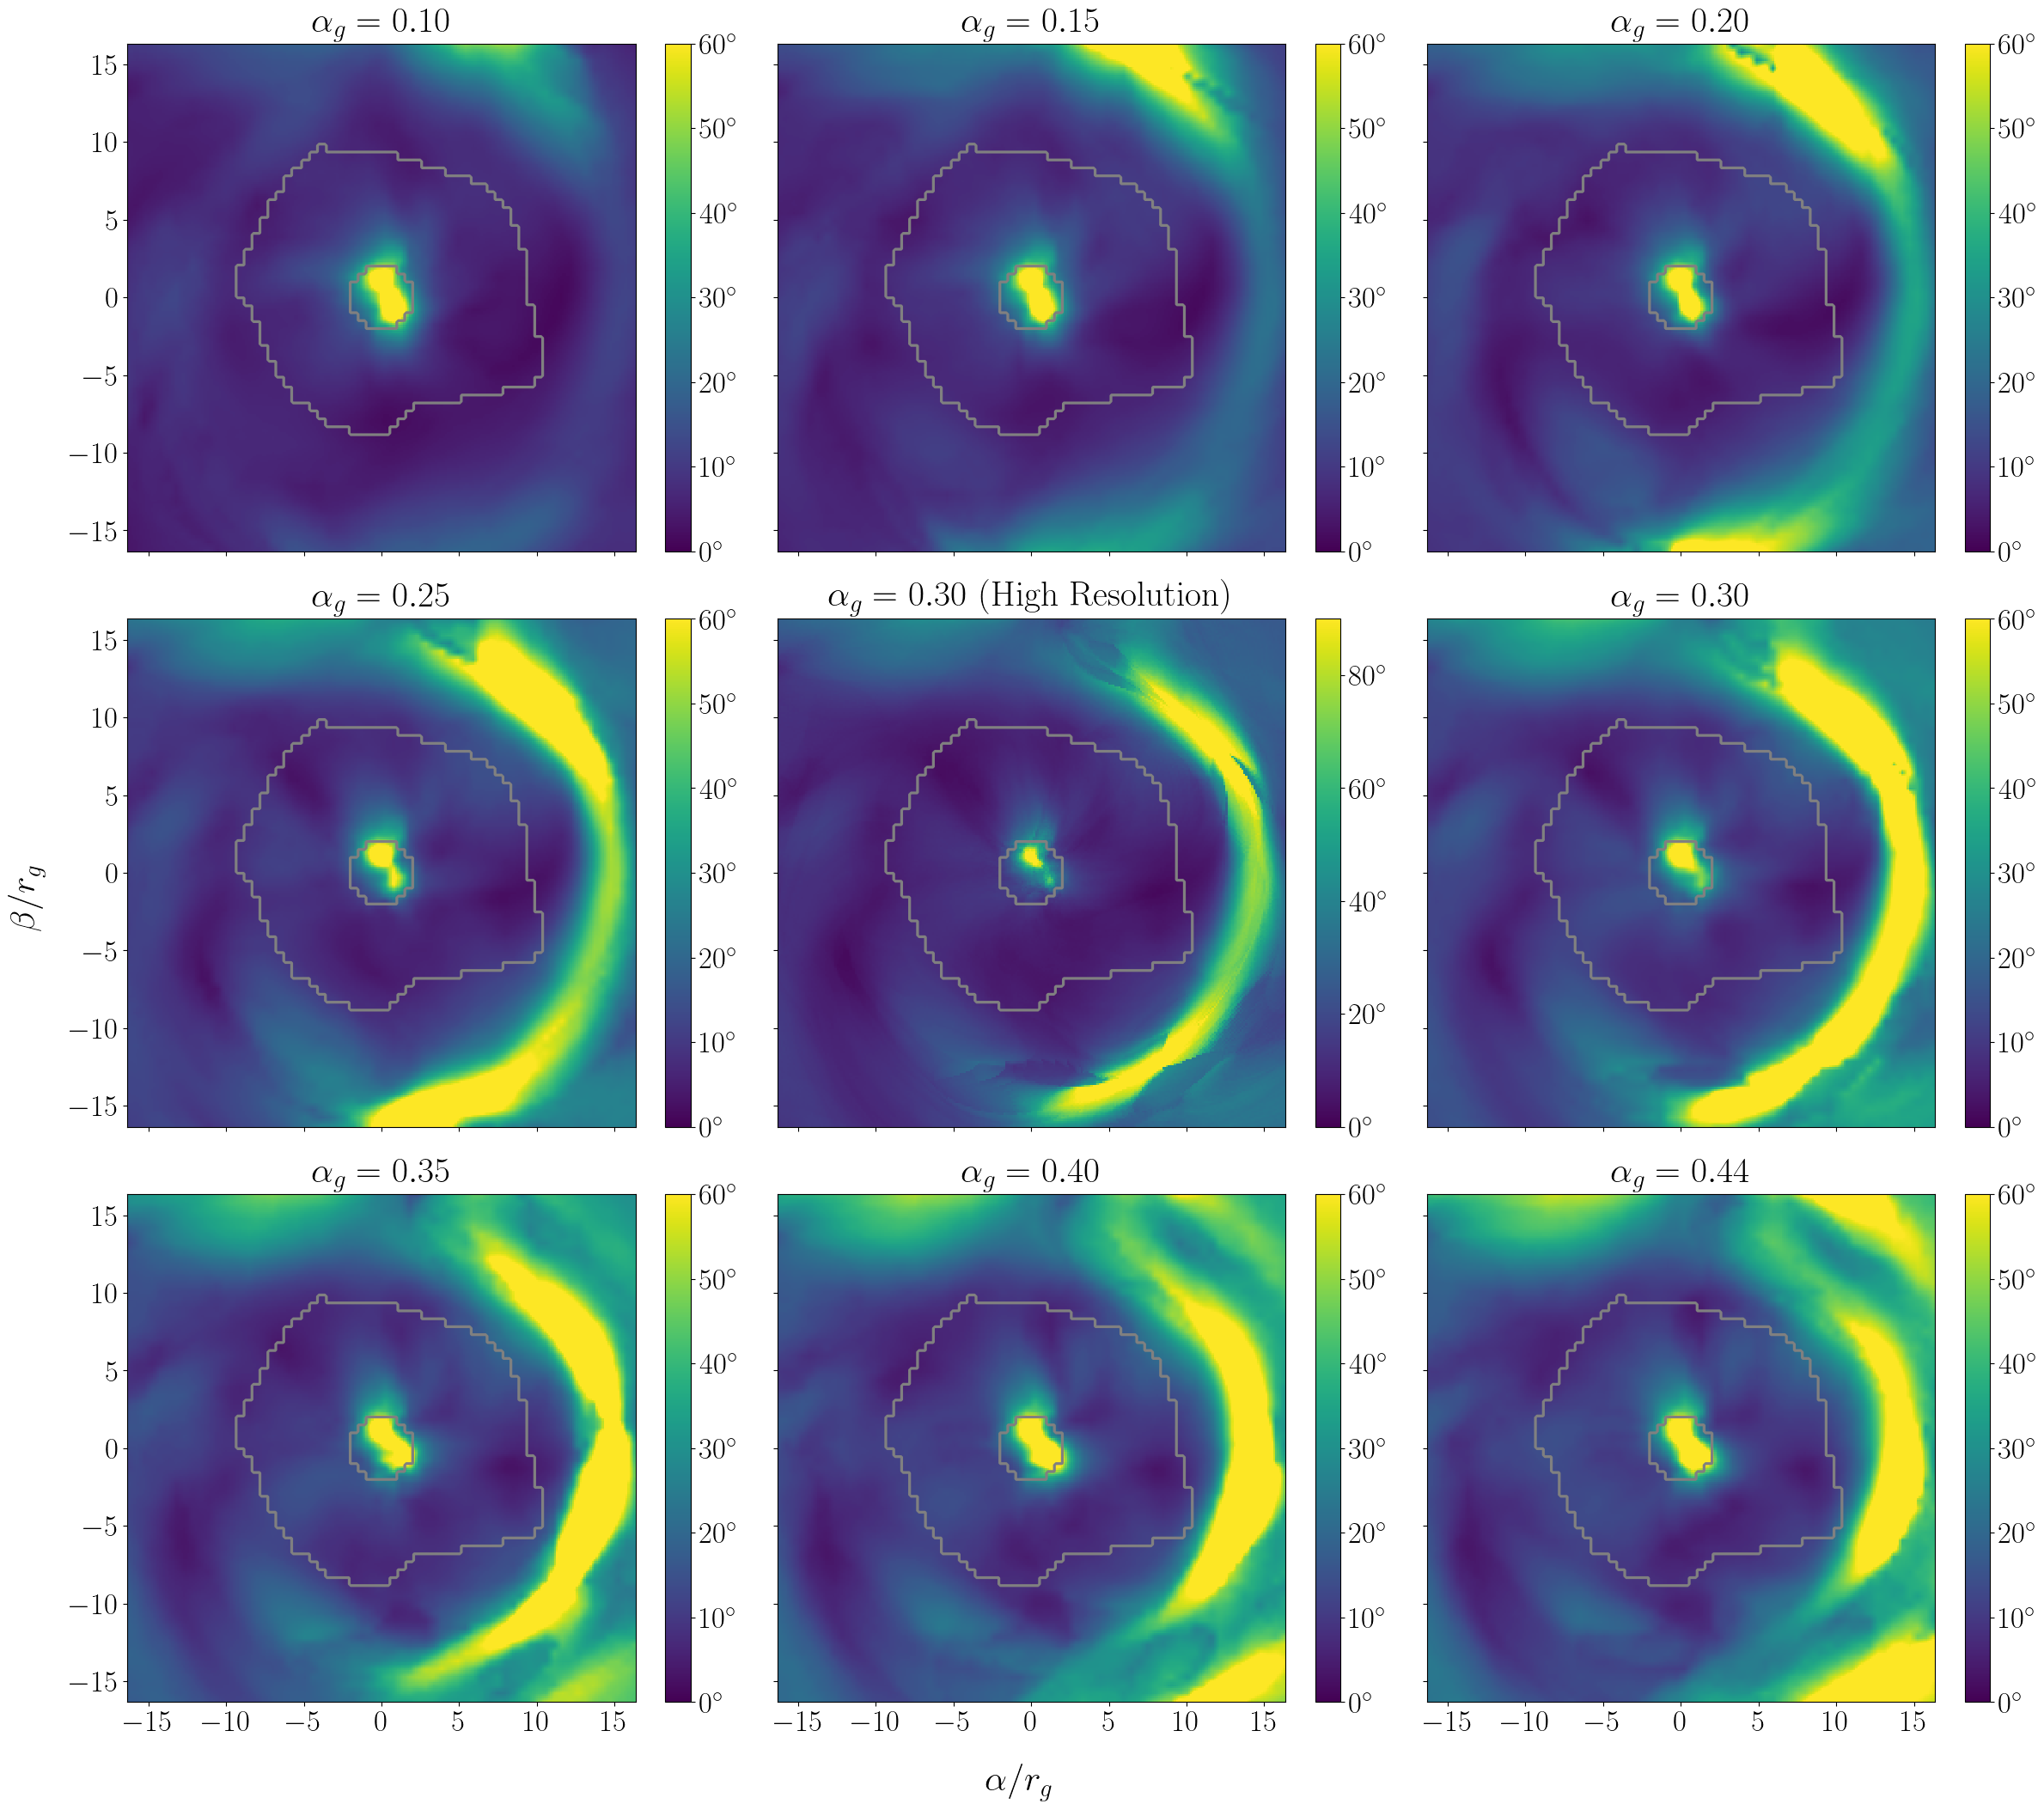

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(24, 21), sharex=True, sharey=True)
alpha_matrix = np.array([[0.1, 0.15, 0.2], [0.25, 0.3, 0.3], [0.35, 0.4, 0.44]])
# data_max_matrix = np.array([[0.1, 0.1, 0.2], [0.3, 0.4, 0.4], [0.5, 0.6, 0.6]])
for i in range(3):
    for j in range(3):
        if i == 1 and j == 1:
            Plot_Background_NoNorm(
                fig,
                axes[i, j],
                phi0_params[1] / np.pi * 180,
                xy_tick_labelsize=25,
                cbar_tick_labelsize=25,
                cbar_label_fontsize=20,
                cbar_label_pad=27,
                cbar_label_y=0.5,
                cbar_label_rotation=270,
                cbar_label_text=r"",  # 自定义Colorbar标签
                # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                # 或者您可以手动指定，例如:
                data_vmin=0,
                data_vmax=90,
                cmap="viridis",
                upscale_factor=1,
                condition=condition,
                title=rf"$\alpha_g={alpha_matrix[i, j]:.2f}$ (High Resolution)",
                title_fontsize=30,
                title_y=10,
                title_x=0.5,
                fmt=0,
                degree=True,
            )
        else:
            Plot_Background_NoNorm(
                fig,
                axes[i, j],
                phi0_params_dict[alpha_matrix[i, j]][1] / np.pi * 180,
                xy_tick_labelsize=25,
                cbar_tick_labelsize=25,
                cbar_label_fontsize=20,
                cbar_label_pad=27,
                cbar_label_y=0.5,
                cbar_label_rotation=270,
                cbar_label_text=r"",  # 自定义Colorbar标签
                # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                # 或者您可以手动指定，例如:
                data_vmin=0,
                data_vmax=60,
                cmap="viridis",
                upscale_factor=4,
                condition=condition,
                title=rf"$\alpha_g={alpha_matrix[i, j]:.2f}$",
                title_fontsize=30,
                title_y=10,
                title_x=0.5,
                fmt=0,
                degree=True,
            )
# fig.suptitle(
#     r"Standard of $\mathcal{A}^{\mathrm{tot}}$",
#     fontsize=36,
#     y=0.93,
# )
fig.supxlabel(r"$\alpha/r_g$", fontsize=30, y=-0.001)
fig.supylabel(r"$\beta/r_g$", fontsize=30, x=0.01)
fig.tight_layout()
# fig.savefig("images/Uncertainty/Std of phi.png")

In [12]:
# theta_mean = []
theta_std = []
for day in [95, 96, 100, 101]:
    with np.load(f"../EHT-Imaging/data_out/{day}.npz") as data:
        theta_std.append(data["arr_1"])  # rad

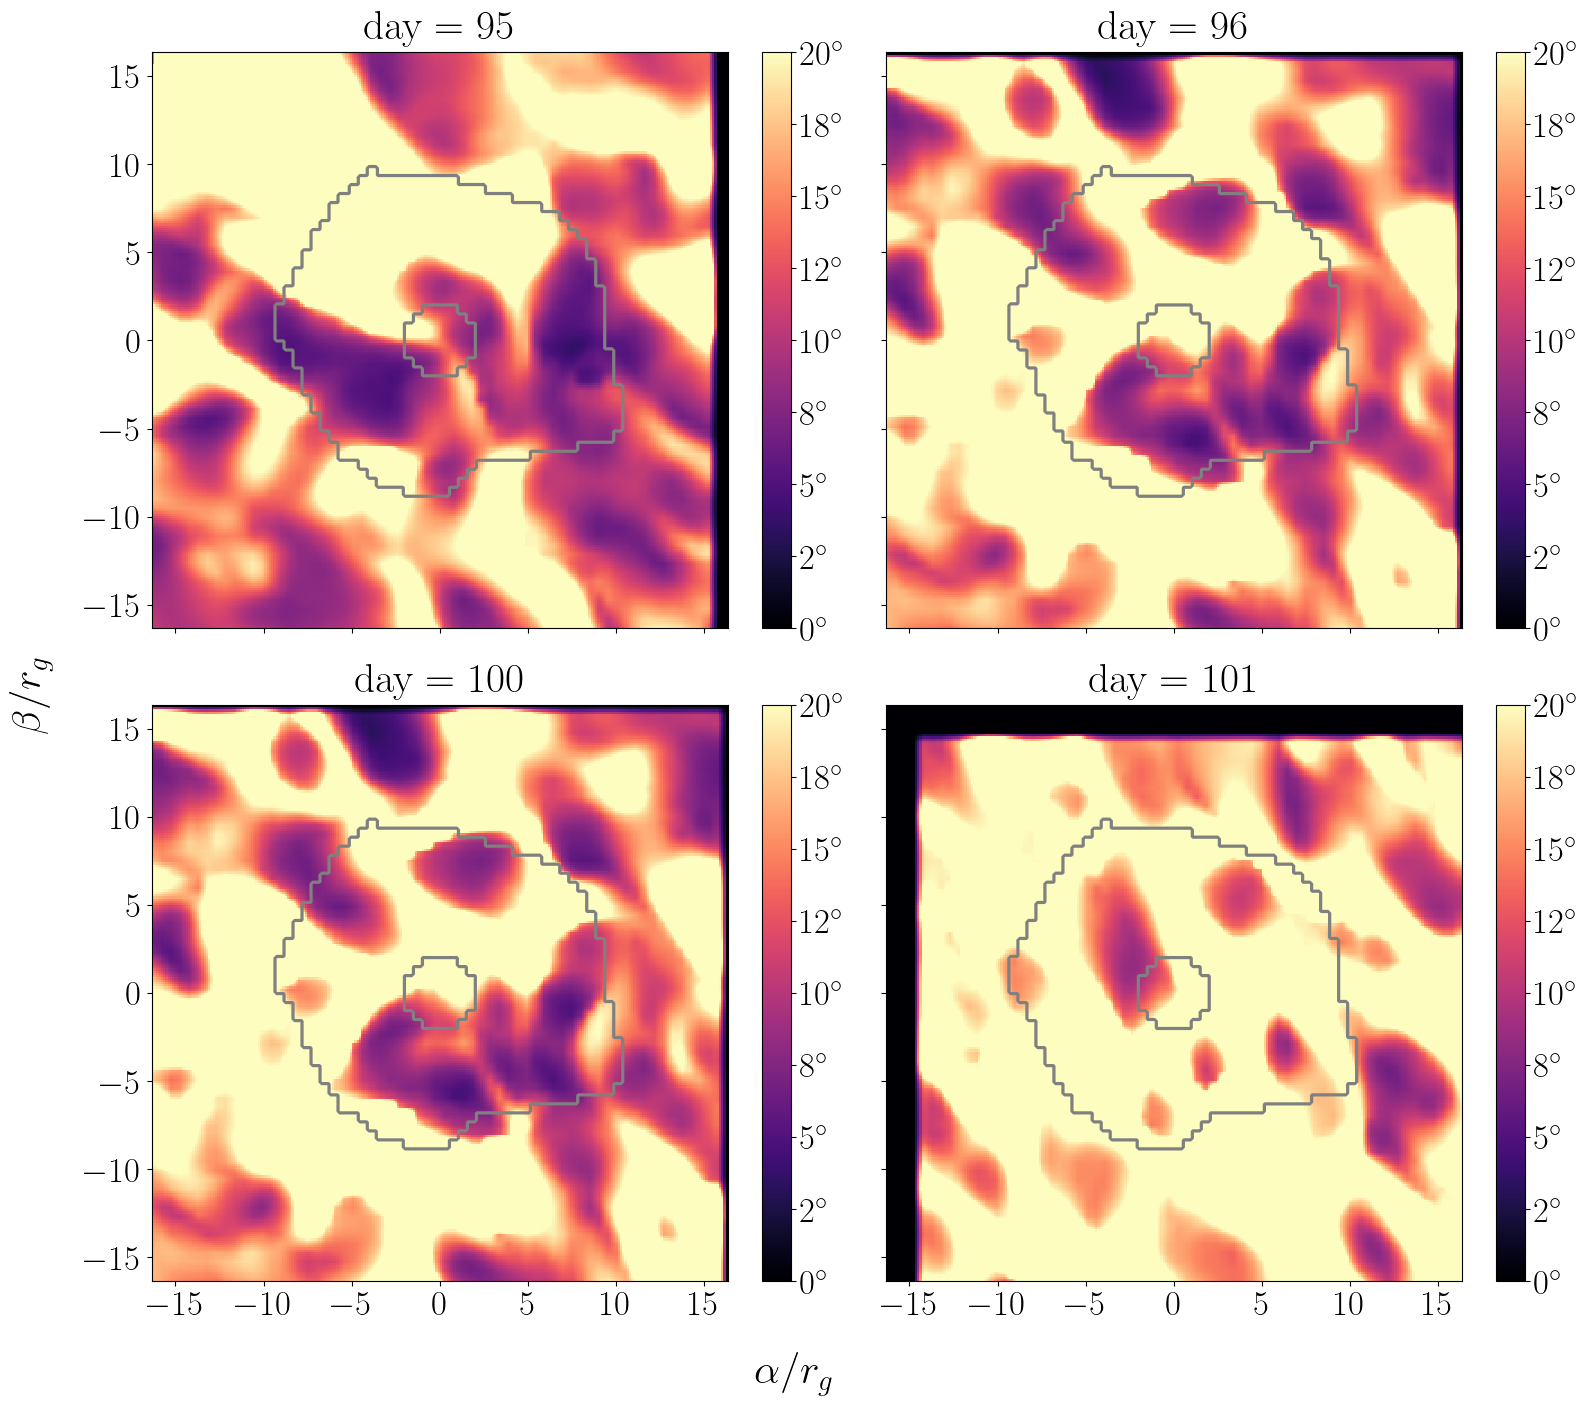

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14), sharex=True, sharey=True)
day_matrix = np.array([[95, 96], [100, 101]])
for i in range(2):
    for j in range(2):
        Plot_Background_NoNorm(
            fig,
            axes[i, j],
            theta_std[i + j] / np.pi * 180,
            xy_tick_labelsize=25,
            cbar_tick_labelsize=25,
            cbar_label_fontsize=20,
            cbar_label_pad=27,
            cbar_label_y=0.5,
            cbar_label_rotation=270,
            cbar_label_text=r"",  # 自定义Colorbar标签
            # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
            # 或者您可以手动指定，例如:
            data_vmin=0,
            data_vmax=20,
            cmap="magma",
            upscale_factor=4,
            condition=condition,
            title=r"$\mathrm{day}" + rf"={day_matrix[i, j]}$",
            title_fontsize=30,
            title_y=10,
            title_x=0.5,
            fmt=0,
            degree=True,
        )
# fig.suptitle(
#     r"Standard of $\mathcal{A}^{\mathrm{tot}}$",
#     fontsize=36,
#     y=0.93,
# )
fig.supxlabel(r"$\alpha/r_g$", fontsize=30, y=-0.001)
fig.supylabel(r"$\beta/r_g$", fontsize=30, x=0.01)
fig.tight_layout()
# fig.savefig("images/Uncertainty/Std of phi.png")

In [ ]:
# theta_mean = []
theta_std_786 = np.load(f"../EHT-Imaging/data_out/std_786.npy", allow_pickle=True)

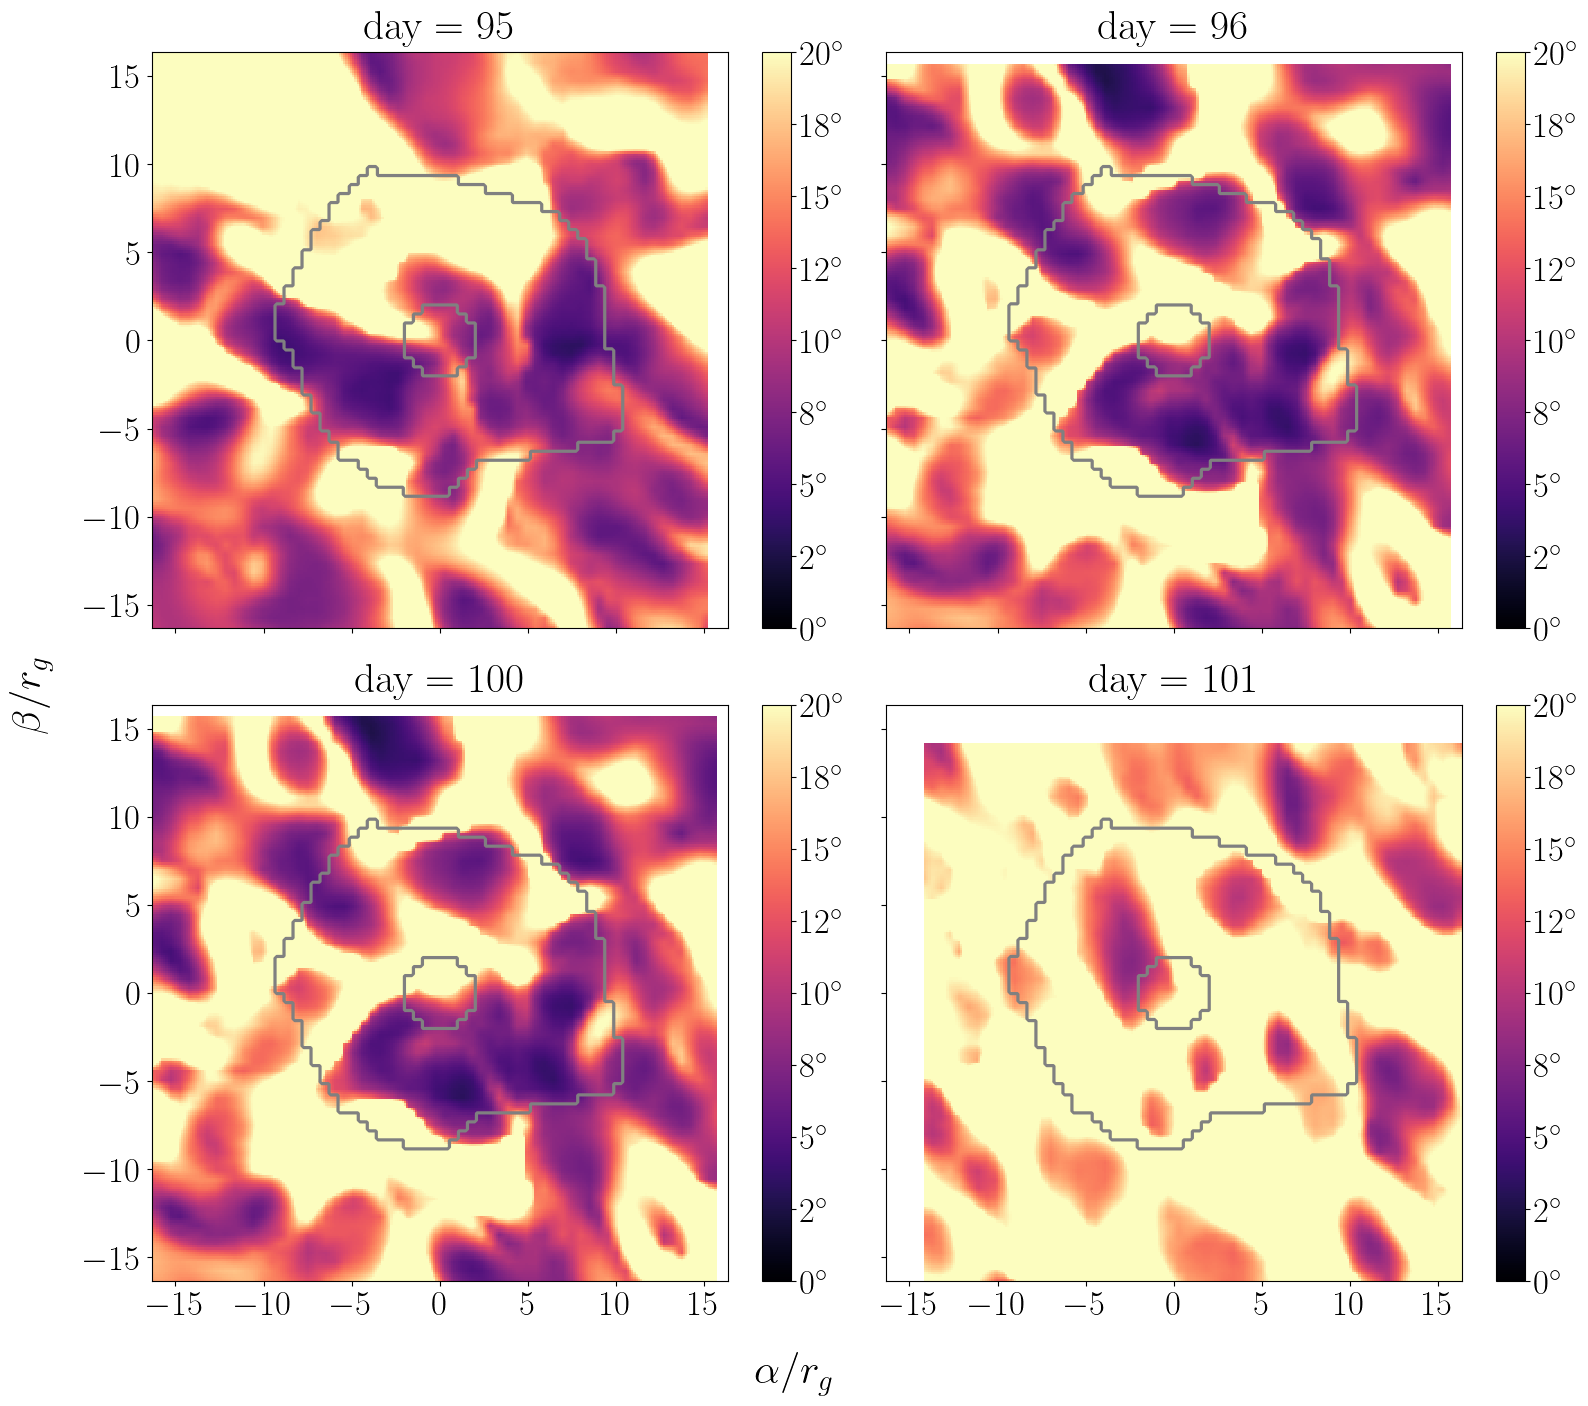

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14), sharex=True, sharey=True)
day_matrix = np.array([[95, 96], [100, 101]])
for i in range(2):
    for j in range(2):
        Plot_Background_NoNorm(
            fig,
            axes[i, j],
            theta_std_786[i + j].reshape(64, 64) / np.pi * 180,
            xy_tick_labelsize=25,
            cbar_tick_labelsize=25,
            cbar_label_fontsize=20,
            cbar_label_pad=27,
            cbar_label_y=0.5,
            cbar_label_rotation=270,
            cbar_label_text=r"",  # 自定义Colorbar标签
            # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
            # 或者您可以手动指定，例如:
            data_vmin=0,
            data_vmax=20,
            cmap="magma",
            upscale_factor=4,
            condition=condition,
            title=r"$\mathrm{day}" + rf"={day_matrix[i, j]}$",
            title_fontsize=30,
            title_y=10,
            title_x=0.5,
            fmt=0,
            degree=True,
        )
# fig.suptitle(
#     r"Standard of $\mathcal{A}^{\mathrm{tot}}$",
#     fontsize=36,
#     y=0.93,
# )
fig.supxlabel(r"$\alpha/r_g$", fontsize=30, y=-0.001)
fig.supylabel(r"$\beta/r_g$", fontsize=30, x=0.01)
fig.tight_layout()
# fig.savefig("images/Uncertainty/Std of phi.png")

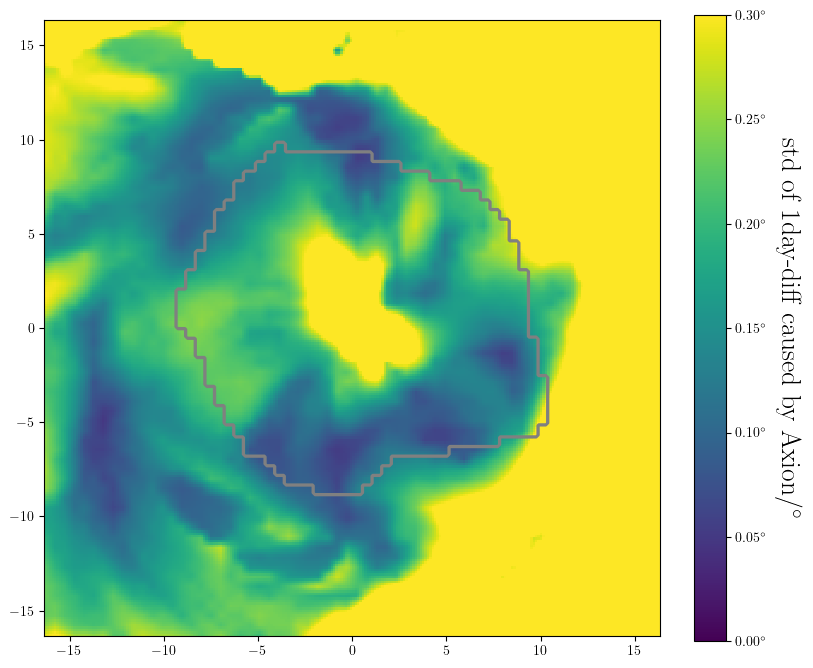

In [81]:
# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
Plot_Background_NoNorm(
    fig,
    ax,
    phi0_params_dict[0.44][1],
    xy_tick_labelsize=10,
    cbar_tick_labelsize=10,
    cbar_label_fontsize=20,
    cbar_label_pad=27,
    cbar_label_y=0.5,
    cbar_label_rotation=270,
    cbar_label_text=r"std of 1day-diff caused by Axion/$^\circ$",  # 自定义Colorbar标签
    # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
    # 或者您可以手动指定，例如:
    data_vmin=0,
    data_vmax=0.3,
    cmap="viridis",
    upscale_factor=4,
    phi0=True,
    condition=condition,
)

# 添加主图的标题和轴标签（可选）
# ax.set_title("64x64 Data Visualization (No Normalization)", fontsize=16)

# 4. 自动调整布局
fig.tight_layout()
# plt.savefig("fig4_1day_diffs_std.png")
# 5. 显示图像
plt.show()

badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optimal parameters not found: Number of calls to function has reached maxfev = 600.
badfit, error Optima

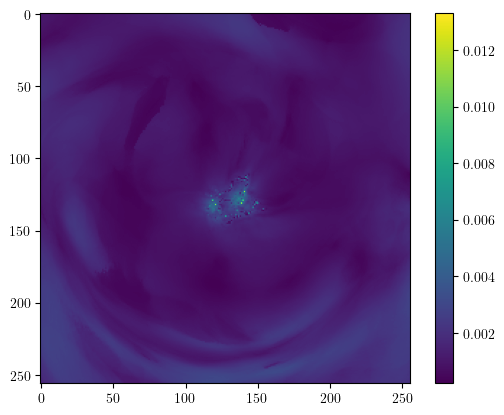

In [62]:
plt.imshow(A_params[1])
plt.colorbar()

In [ ]:
diffs_axion_evpa = np.load("diffs_axion_evpa.npy")

In [ ]:
rg_per_pixel = 0.51073125
condition2to9 = np.array(
    [
        [
            2 <= np.sqrt((i - 31.5) ** 2 + (j - 31.5) ** 2) * rg_per_pixel <= 9
            for j in range(64)
        ]
        for i in range(64)
    ]
)
condition2to9 = np.array(condition2to9, dtype=np.float16)
condition2to9[condition2to9 == False] = np.nan

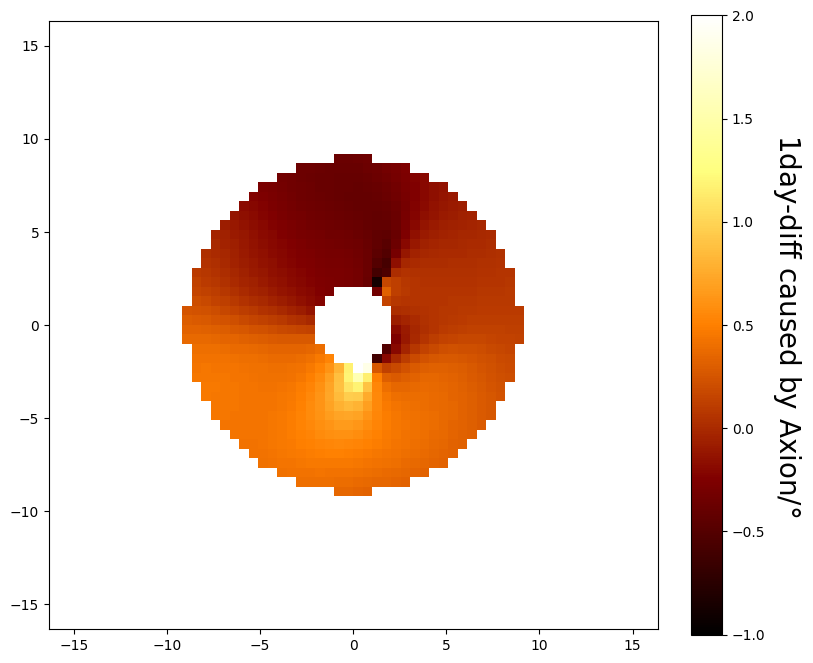

In [ ]:
# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
Plot_Background_NoNorm(
    fig,
    ax,
    diffs_axion_evpa / np.pi * 180 * condition2to9,
    xy_tick_labelsize=10,
    cbar_tick_labelsize=10,
    cbar_label_fontsize=20,
    cbar_label_pad=27,
    cbar_label_y=0.5,
    cbar_label_rotation=270,
    cbar_label_text=r"1day-diff caused by Axion/$\degree$",  # 自定义Colorbar标签
    # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
    # 或者您可以手动指定，例如:
    data_vmin=-1,
    data_vmax=2,
    cmap="afmhot",
)

# 添加主图的标题和轴标签（可选）
# ax.set_title("64x64 Data Visualization (No Normalization)", fontsize=16)

# 4. 自动调整布局
fig.tight_layout()
plt.savefig("fig4_1day_diffs.png")
# 5. 显示图像
plt.show()

In [ ]:
A_params = np.load("../A_params.npy")

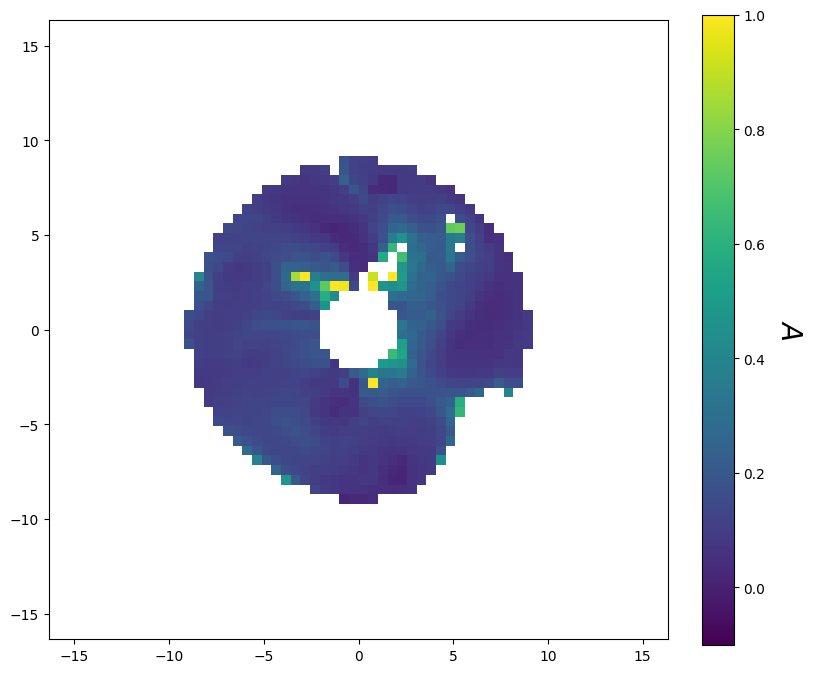

In [ ]:
# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
Plot_Background_NoNorm(
    fig,
    ax,
    A_params[2] / np.pi * 180 * condition2to9,
    xy_tick_labelsize=10,
    cbar_tick_labelsize=10,
    cbar_label_fontsize=20,
    cbar_label_pad=27,
    cbar_label_y=0.5,
    cbar_label_rotation=270,
    cbar_label_text=r"$A$",  # 自定义Colorbar标签
    # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
    # 或者您可以手动指定，例如:
    data_vmin=1,
    data_vmax=0,
    cmap="viridis",
)

# 添加主图的标题和轴标签（可选）
# ax.set_title("64x64 Data Visualization (No Normalization)", fontsize=16)

# 4. 自动调整布局
fig.tight_layout()
plt.savefig("fig4_uncertainty_A.png")
# 5. 显示图像
plt.show()

In [ ]:
phi0_params = np.load("../phi0_params.npy")

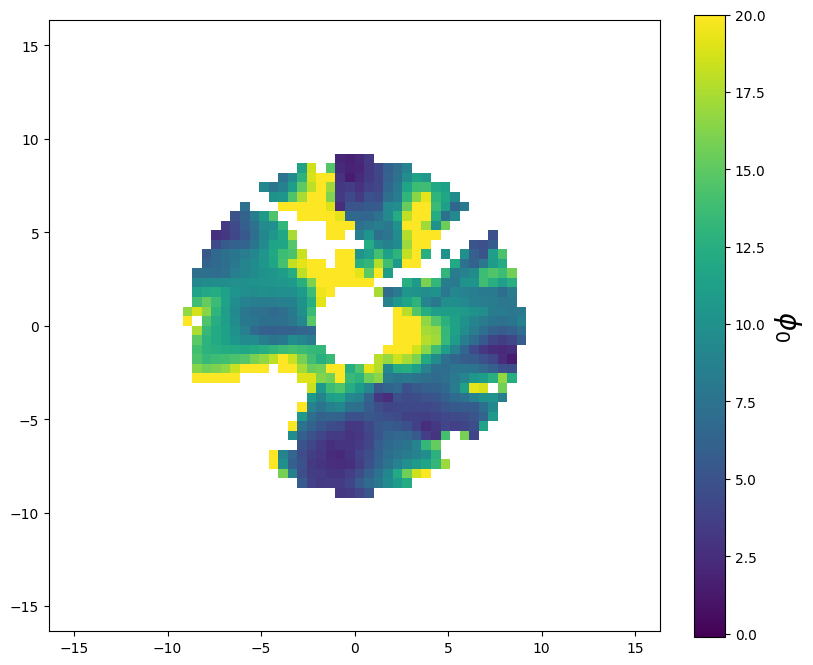

In [ ]:
# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
Plot_Background_NoNorm(
    fig,
    ax,
    phi0_params[2] / np.pi * 180 * condition2to9,
    xy_tick_labelsize=10,
    cbar_tick_labelsize=10,
    cbar_label_fontsize=20,
    cbar_label_pad=27,
    cbar_label_y=0.5,
    cbar_label_rotation=270,
    cbar_label_text=r"$\phi_0$",  # 自定义Colorbar标签
    # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
    # 或者您可以手动指定，例如:
    data_vmin=20,
    data_vmax=0,
    cmap="viridis",
)

# 添加主图的标题和轴标签（可选）
# ax.set_title("64x64 Data Visualization (No Normalization)", fontsize=16)

# 4. 自动调整布局
fig.tight_layout()
# plt.savefig("fig4_uncertainty_A.png")
# 5. 显示图像
plt.show()

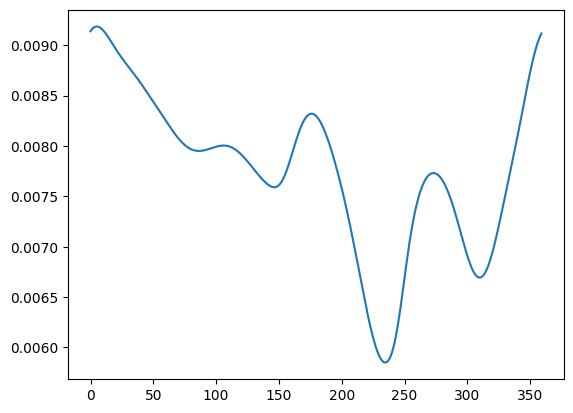

In [16]:
plt.plot(A_1d_r_9[55])

In [106]:
# 自定义白→红 colormap
white_red = LinearSegmentedColormap.from_list("white_red", ["white", "red"])

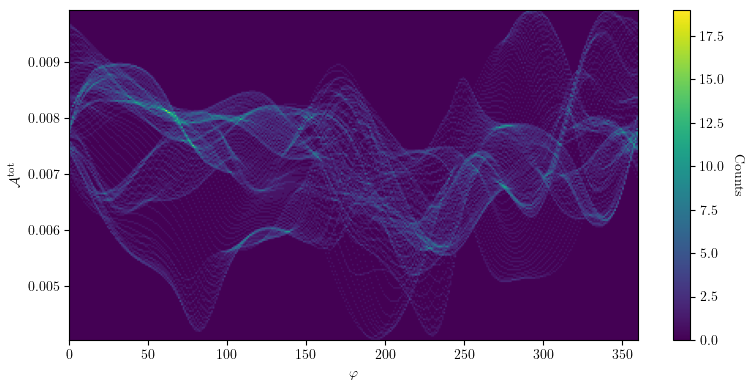

In [ ]:
# 假设 data 是你已经读取好的 ndarray，形状为 (num_samples, num_phi)
# 如果你已经有了 data，就不用重复定义

num_samples, num_phi = A_1d_r_9.shape
phi = np.arange(num_phi)

# 展开为所有样本的 (phi, f) 坐标
phi_all = np.tile(phi, num_samples)
f_all = A_1d_r_9.flatten()

# ===== 图2：2D 直方图（像你的图） =====
# plt.subplot(1, 2, 2)
hist, xedges, yedges = np.histogram2d(phi_all, f_all, bins=[num_phi, 200])
plt.figure(figsize=(8, 4))
plt.imshow(
    hist.T,
    origin="lower",
    aspect="auto",
    cmap="viridis",
    extent=[0, 360, f_all.min(), f_all.max()],
)
# plt.colorbar().set_label(label="Counts", rotation=270, labelpad=15)
plt.xlabel(r"$\varphi$")
plt.ylabel(r"$\mathcal{A}^{\mathrm{tot}}$")
# plt.title('EVPA Observation Histogram')

plt.tight_layout()
plt.show()

In [37]:
from utils.libanaly import CircleCalc
from scipy.stats import norm

In [17]:
formatter0 = FuncFormatter(lambda x, pos: rf"${x:.{0}f}^\circ$")
formatter1 = FuncFormatter(lambda x, pos: rf"${x:.{1}f}^\circ$")

/tmp/ipykernel_157205/1738423125.py:70: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax_hist.plot(y_curve, x_curve, 'r-', linewidth=1, label='Gaussian PDF',color="black")


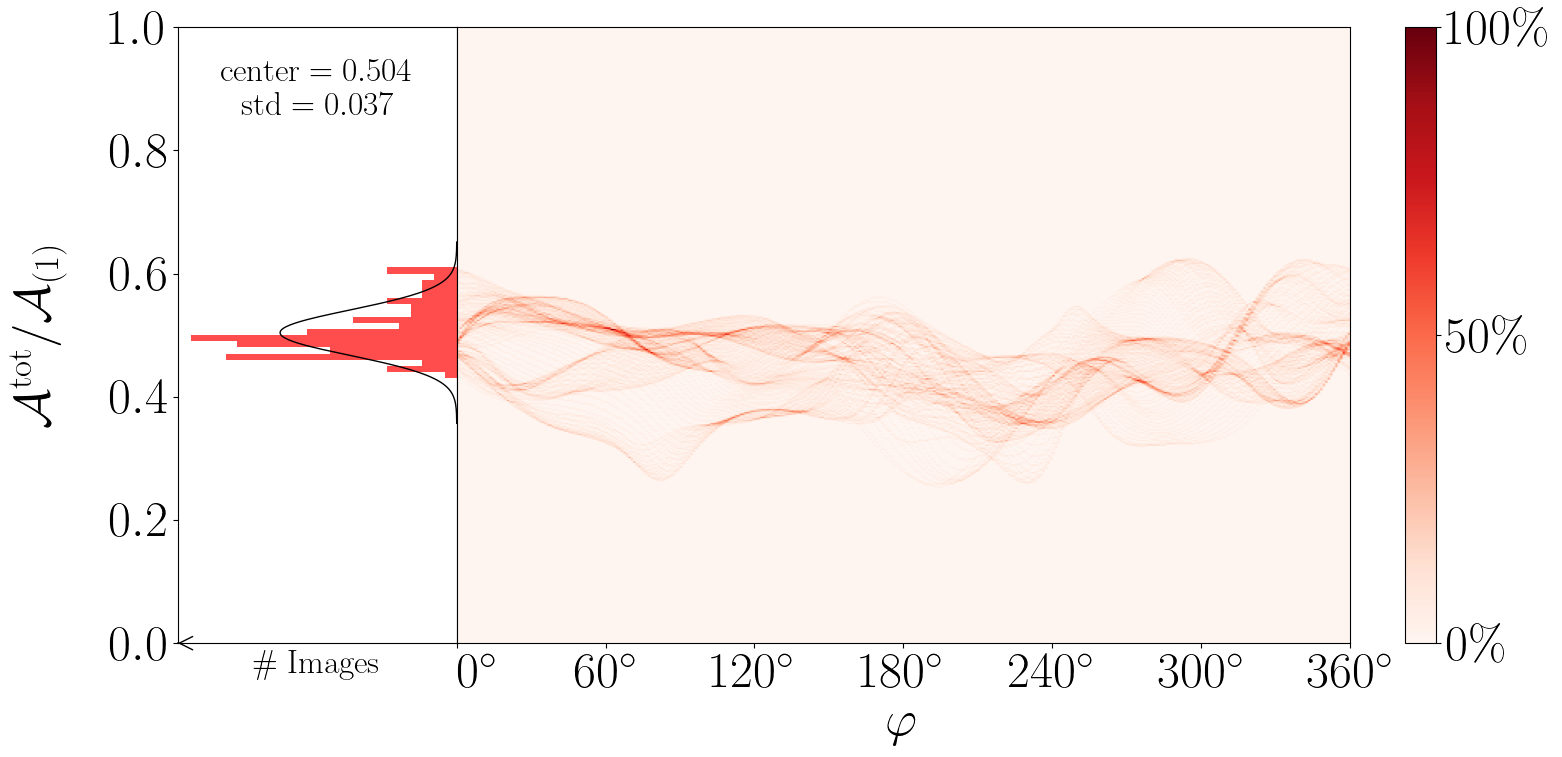

In [ ]:
# ===== 假设已有数据 =====
num_samples, num_phi = A_1d_r_9.shape
phi = np.arange(num_phi)

phi_all = np.tile(phi, num_samples)
f_all = A_1d_r_9.flatten() * 10 * 2 * np.pi  # 归一化

ymin, ymax = (0, 1)

hist, xedges, yedges = np.histogram2d(
    phi_all,
    f_all,
    bins=[num_phi, 400],
    range=[[phi.min(), phi.max()], [ymin, ymax]],
    density=True,
)


# ===== 创建 figure 和 axes =====
fig, (ax_hist, ax_img) = plt.subplots(
    1,
    2,
    figsize=(18, 8),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 4], "wspace": 0},
)

# ===== 左图：竖直直方图（朝左） =====
data_last = A_1d_r_9[:, 0] * 10 * 2 * np.pi  # 归一化
ax_hist.hist(
    data_last,
    bins=100,
    orientation="horizontal",
    density=True,
    color="red",
    alpha=0.7,
    range=(ymin, ymax),
)
ax_hist.set_ylabel(
    r"$\mathcal{A}^{\mathrm{tot}}/\mathcal{A}_{\left(1\right)}$",
    fontsize=36,
    labelpad=30,
)  # ← y 轴标签字体
ax_hist.set_xlabel(r"\# Images", fontsize=24, labelpad=5)  # ← x 轴标签字体
ax_hist.set_xticks([])
ax_hist.set_xlim(left=0)
ax_hist.invert_xaxis()
ax_hist.set_ylim(ymin, ymax)
# ax_hist.yaxis.set_major_formatter(formatter1)  # y 轴刻度格式
ax_hist.tick_params(axis="y", labelsize=36)  # ← y 轴刻度字体

_mean, _sigma = fit_gaussian2(
    data_last,
    rm_nan=True,
    plot_failed=False,
    threshold=np.nan,
    p_value_threshold=0.001,
    plot=False,
    bins=20,
    nomean=True,
)


x_curve = np.linspace(_mean - 4 * _sigma, _mean + 4 * _sigma, 200)

# 计算对应 x 值的 高斯概率密度函数 (PDF) 值
y_curve = norm.pdf(x_curve, _mean, _sigma)


# --- 5. 在 ax_hist 上绘制曲线 ---
# 这就是您要的步骤：在 ax_hist 上画线
ax_hist.plot(y_curve, x_curve, "r-", linewidth=1, label="Gaussian PDF", color="black")

ax_hist.text(
    0.5,
    0.95,  # x, y 坐标 (5% x, 95% y)
    r"$\mathrm{center}=" + f"{_mean:.3f}$ \n" + r"$\mathrm{std}=" + f"{_sigma:.3f}$",
    transform=ax_hist.transAxes,  # ★★★ 使用坐标轴的相对坐标
    fontsize=24,
    va="top",  # 垂直对齐 = 顶部
    ha="center",  # 水平对齐 = 左侧
)

# ===== 给 ax_hist 的 x 轴加箭头（朝左） =====
x_left, x_right = ax_hist.get_xlim()

ax_hist.annotate(
    "",
    xy=(
        x_left,
        ymin,
    ),  # 箭头尖端在左端（数值大的一端）
    xytext=(
        x_left - 0.01,
        ymin,
    ),  # 起点在右端（数值小的一端）
    arrowprops=dict(
        arrowstyle="->",
        lw=1,
        color="black",
        shrinkA=0,
        shrinkB=0,
        mutation_scale=24,  # 箭头大小
    ),
    annotation_clip=False,
)

# ===== 右图：imshow =====
im = ax_img.imshow(
    hist.T,
    origin="lower",
    aspect="auto",
    cmap="Reds",
    extent=[0, 360, ymin, ymax],
)
ax_img.set_xlabel(r"$\varphi$", fontsize=36)  # ← x 轴标签字体
ax_img.set_ylabel("", fontsize=36)  # ← y 轴标签（留空但仍设置）
ax_img.set_ylim(ymin, ymax)
ax_img.set_xticks([0, 60, 120, 180, 240, 300, 360])
ax_img.get_xticklabels()[0].set_ha("left")
ax_img.xaxis.set_major_formatter(formatter0)  # ← x 轴刻度格式
ax_img.tick_params(axis="x", labelsize=36)  # ← x 轴刻度字体
ax_img.tick_params(axis="y", labelsize=36)  # ← y 轴刻度字体（虽然隐藏，但可保留）

# 去掉右图左侧的 y 轴刻度、标签、边框
ax_img.yaxis.set_ticks_position("none")
# ax_img.spines["left"].set_visible(False)

# ===== 颜色条 =====
cbar = plt.colorbar(im, ax=ax_img)
cbar.ax.tick_params(labelsize=36)  # ← colorbar 刻度字体
cbar.set_ticks([0, hist.max() / 2, hist.max()])
cbar.set_ticklabels([r"0\%", r"50\%", r"100\%"])  # ← 这些继承上面字体大小设置
# cbar.set_label("counts", rotation=270, labelpad=15, fontsize=14)  # ← 如果想加标签的话

# ===== 整体布局 =====
plt.subplots_adjust(wspace=0)
# plt.savefig("images/Uncertainty/A histogram.png")

In [24]:
ax_img.get_xticklabels()[0].get_position()

(np.int64(0), 0)

<>:78: SyntaxWarning: invalid escape sequence '\c'
<>:78: SyntaxWarning: invalid escape sequence '\c'
<>:78: SyntaxWarning: invalid escape sequence '\c'
<>:78: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_157205/2379271005.py:78: SyntaxWarning: invalid escape sequence '\c'
  r"$\mathrm{center}="+f"{_mean:.1f}^\circ$ \n"+ r"$\mathrm{std}="+f"{_sigma:.1f}^\circ$",
/tmp/ipykernel_157205/2379271005.py:78: SyntaxWarning: invalid escape sequence '\c'
  r"$\mathrm{center}="+f"{_mean:.1f}^\circ$ \n"+ r"$\mathrm{std}="+f"{_sigma:.1f}^\circ$",
/tmp/ipykernel_157205/2379271005.py:74: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax_hist.plot(y_curve, x_curve, 'r-', linewidth=1, label='Gaussian PDF',color="black")


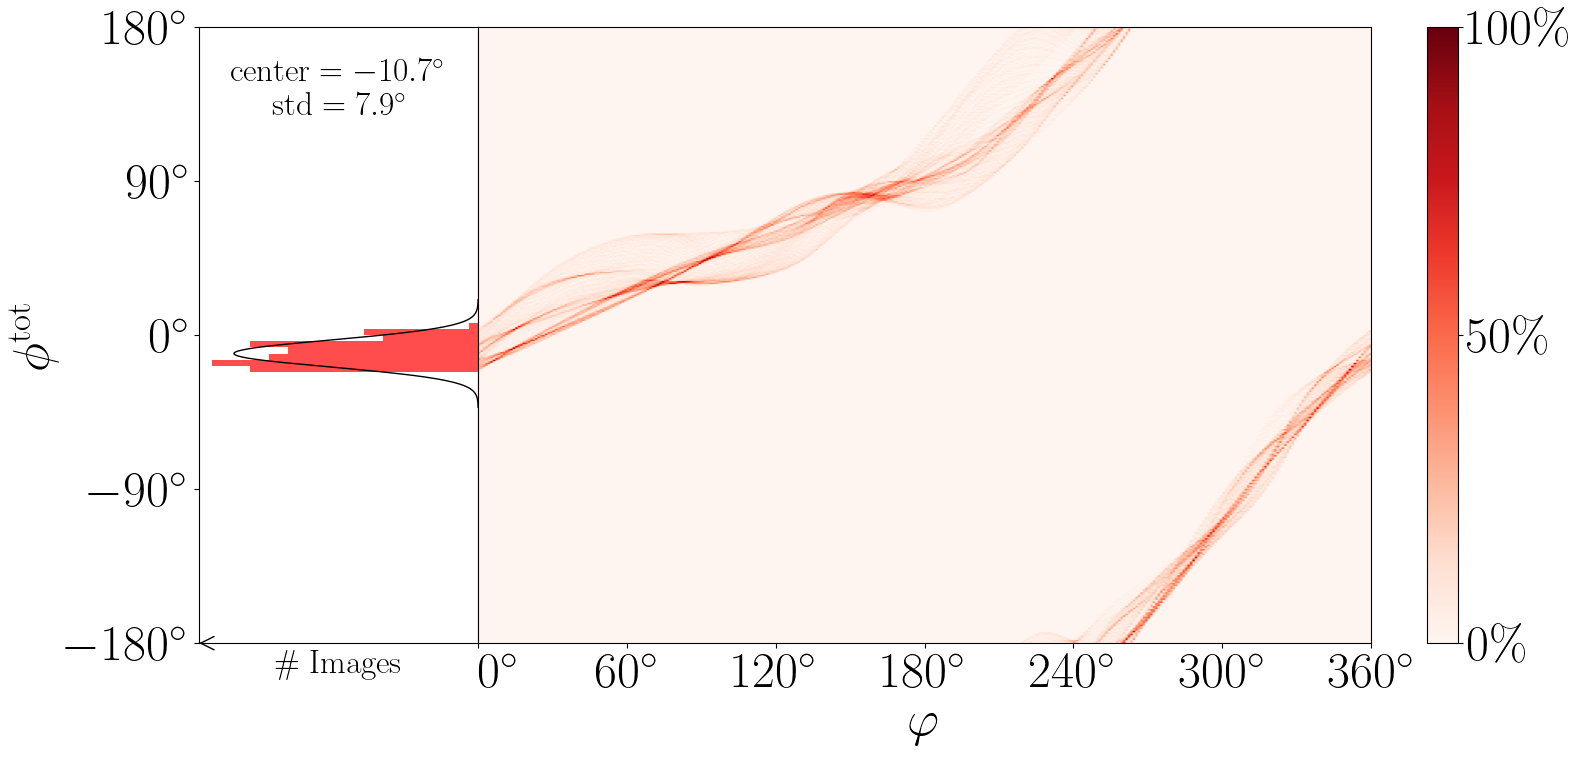

In [ ]:
num_samples, num_phi = phi0_1d_r_9.shape
phi = np.arange(num_phi)

phi_all = np.tile(phi, num_samples)
f_all = phi0_1d_r_9.flatten()
f_all = f_all - np.pi / 8 * 6
f_all = CircleCalc.normalize(f_all) / np.pi * 180

# y 轴范围和 A 一样
# ymin, ymax = (f_all.min(), f_all.max())
ymin, ymax = -180, 180

# 计算 2D 直方图，density=True 保持百分比
hist, xedges, yedges = np.histogram2d(
    phi_all,
    f_all,
    bins=[num_phi, 400],
    range=[[phi.min(), phi.max()], [ymin, ymax]],
    density=True,
)

# ===== 创建 figure 和 axes =====
fig, (ax_hist, ax_img) = plt.subplots(
    1,
    2,
    figsize=(18, 8),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 4], "wspace": 0},
)

# ===== 左图：竖直直方图（朝左） =====
data_last = CircleCalc.normalize(phi0_1d_r_9[:, 0] - np.pi / 8 * 6) / np.pi * 180
ax_hist.hist(
    data_last,
    bins=100,
    orientation="horizontal",
    density=True,
    color="red",
    alpha=0.7,
    range=(ymin, ymax),
)

ax_hist.set_ylabel(r"$\phi^{\mathrm{tot}}$", fontsize=36)  # y 轴标签字体
ax_hist.set_xlim(left=0)
ax_hist.set_xticks([])
ax_hist.invert_xaxis()
ax_hist.set_ylim(ymin, ymax)
ax_hist.set_yticks([-180, -90, 0, 90, 180])
# ax_hist.set_yticklabels([-180, -90, 0, 90, 180])
ax_hist.yaxis.set_major_formatter(formatter0)  # y 轴刻度格式
ax_hist.tick_params(axis="y", labelsize=36)  # y 轴刻度字体


_mean, _sigma = fit_gaussian2(
    data_last,
    rm_nan=True,
    plot_failed=False,
    threshold=np.nan,
    p_value_threshold=0.001,
    plot=False,
    bins=20,
    nomean=True,
)


x_curve = np.linspace(_mean - 4 * _sigma, _mean + 4 * _sigma, 200)

# 计算对应 x 值的 高斯概率密度函数 (PDF) 值
y_curve = norm.pdf(x_curve, _mean, _sigma)


# --- 5. 在 ax_hist 上绘制曲线 ---
# 这就是您要的步骤：在 ax_hist 上画线
ax_hist.plot(y_curve, x_curve, "r-", linewidth=1, label="Gaussian PDF", color="black")

ax_hist.text(
    0.5,
    0.95,  # x, y 坐标 (5% x, 95% y)
    r"$\mathrm{center}="
    + f"{_mean:.1f}^\circ$ \n"
    + r"$\mathrm{std}="
    + f"{_sigma:.1f}^\circ$",
    transform=ax_hist.transAxes,  # ★★★ 使用坐标轴的相对坐标
    fontsize=24,
    va="top",  # 垂直对齐 = 顶部
    ha="center",  # 水平对齐 = 左侧
)

# ===== 给 ax_hist 的 x 轴加箭头（朝左） =====
x_left, x_right = ax_hist.get_xlim()

ax_hist.annotate(
    "",
    xy=(
        x_left,
        ymin,
    ),  # 箭头尖端在左端（数值大的一端）
    xytext=(
        x_left - 0.000001,
        ymin,
    ),  # 起点在右端（数值小的一端）
    arrowprops=dict(
        arrowstyle="->",
        lw=1,
        color="black",
        shrinkA=0,
        shrinkB=0,
        mutation_scale=24,  # 箭头大小
    ),
    annotation_clip=False,
)

# ===== 右图：imshow =====
im = ax_img.imshow(
    hist.T,
    origin="lower",
    aspect="auto",
    cmap="Reds",
    extent=[0, 360, ymin, ymax],
)
ax_img.set_xlabel(r"$\varphi$", fontsize=36)  # x 轴标签字体
ax_hist.set_xlabel(r"\# Images", fontsize=24, labelpad=5)  # ← x 轴标签字体
ax_img.set_ylim(ymin, ymax)
ax_img.set_xticks([0, 60, 120, 180, 240, 300, 360])
ax_img.get_xticklabels()[0].set_ha("left")
ax_img.xaxis.set_major_formatter(formatter0)  # ← x 轴刻度格式
ax_img.tick_params(axis="x", labelsize=36)  # x 轴刻度字体
ax_img.tick_params(axis="y", labelsize=36)  # y 轴刻度字体（虽然隐藏）

# 去掉右图左侧的 y 轴刻度、标签、边框
ax_img.yaxis.set_ticks_position("none")
# ax_img.spines["left"].set_visible(False)

# ===== 颜色条 =====
cbar = plt.colorbar(im, ax=ax_img)
cbar.ax.tick_params(labelsize=36)  # colorbar 刻度字体
cbar.set_ticks([0, hist.max() / 2, hist.max()])
cbar.set_ticklabels([r"0\%", r"50\%", r"100\%"])
# cbar.set_label("counts", rotation=270, labelpad=15, fontsize=14)  # 可选 colorbar 标签

# ===== 调整布局 =====
plt.subplots_adjust(wspace=0)
# plt.savefig("images/Uncertainty/phi histogram.png")

In [68]:
# 读取两个图片并上下拼接，默认白色背景
from PIL import Image

img1 = Image.open("images/Uncertainty/A histogram.png")
img2 = Image.open("images/Uncertainty/phi histogram.png")
total_height = img1.height + img2.height
total_width = np.max([img1.width, img2.width])
new_img = Image.new("RGB", (total_width, total_height), (255, 255, 255))
new_img.paste(img1, (total_width - img1.width, 0))
new_img.paste(img2, (total_width - img2.width, img1.height))
new_img.save("images/Uncertainty/A_phi_histograms.png")